# 02 · Radial velocities with a cross-correlation (UNICOR)

**What you'll learn**

- the cross-correlation function (CCF): built by hand, then with `unicor.ccf_vs_velocity`
- the RV as the CCF peak, and its uncertainty from the peak's shape (Zucker 2003)
- how SPARTA combines the CCFs of several orders, and how to check the error bars against a
  simulated truth
- the full pipeline on real NRES spectra of TOI-677, with a PHOENIX template

In [1]:
import copy

import numpy as np
import matplotlib.pyplot as plt

import unicor
from sparta import CCF1d, Observations, Template, instruments
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import (EXTRA_COLOR, GREY, MODEL_COLOR, apply_style, plot_curve, plot_data,
                             plot_points)

apply_style()
c = unicor.C_KMS                     # speed of light, km/s

## 1. The CCF by hand

The idea: slide a template across the observed spectrum and, at every trial shift, measure how
well the two match. On a log-λ grid (notebook 01) a shift of *k* pixels is one velocity, so the
match as a function of *k* is a function of velocity, and it peaks at the star's RV.

A toy "star": 25 Gaussian lines on a 0.5 km/s log-λ grid, observed at 12.3 km/s with a little noise.

In [2]:
rng = np.random.default_rng(0)
centres, depths = rng.uniform(5002, 5048, 25), rng.uniform(0.2, 0.7, 25)

def toy_star(wave):
    """Normalised spectrum: 25 Gaussian absorption lines of σ = 3 km/s."""
    sigma = 3.0 / c * centres
    return 1 - np.sum(depths * np.exp(-0.5 * ((wave[:, None] - centres) / sigma) ** 2), axis=1)

dv, v_true = 0.5, 12.3                                     # km/s
wave, _ = unicor.log_lambda_grid(5000.0, 5050.0, dv)
observed = toy_star(wave / unicor.doppler_factor(v_true)) + 0.02 * rng.standard_normal(wave.size)

To scan ±K pixels the template must also exist K pixels beyond each end of the observed grid,
so every lag compares the *same* observed pixels (`unicor.extend_log_grid`). At lag *k* the
match is the Pearson correlation of the observed pixels with the template moved by *k*:

In [3]:
K = 40                                                     # lags each side: ±20 km/s
template = toy_star(unicor.extend_log_grid(wave, K))       # N + 2K pixels
N = wave.size

lags = np.arange(-K, K + 1)
ccf_hand = np.array([np.corrcoef(observed, template[K - k: K - k + N])[0, 1] for k in lags])

v, ccf = unicor.ccf_vs_velocity(template, observed, wave)
print(f"max |by hand - unicor.ccf_vs_velocity| = {np.max(np.abs(ccf - ccf_hand)):.1e}")

max |by hand - unicor.ccf_vs_velocity| = 1.1e-14


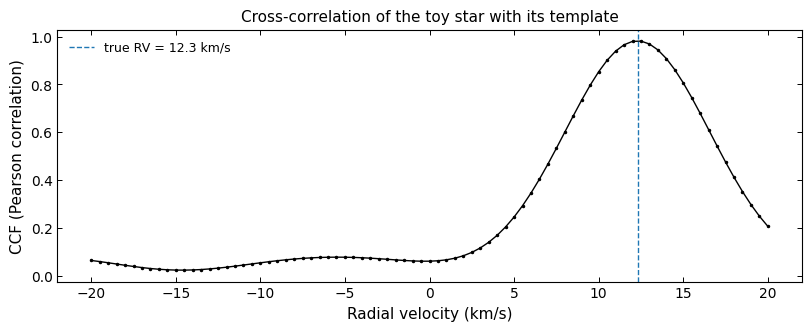

In [4]:
fig, ax = plt.subplots()
plot_curve(ax, v, ccf, marker=".", ms=3)
ax.axvline(v_true, color=EXTRA_COLOR, ls="--", lw=1, label=f"true RV = {v_true} km/s")
ax.set_xlabel("Radial velocity (km/s)")
ax.set_ylabel("CCF (Pearson correlation)")
ax.set_title("Cross-correlation of the toy star with its template")
ax.legend()
plt.show()

## 2. The peak and its uncertainty

The RV is the peak of the CCF, located between lags with a parabola (`unicor.subpixel_peak`).
Its uncertainty follows from the CCF's shape at the peak (Zucker 2003):

$$\sigma_v^2 = -\left[N\,\frac{C''(v)\,C(v)}{1 - C^2(v)}\right]^{-1}$$

A sharper (larger $|C''|$) and higher ($C$ closer to 1) peak, and more independent pixels $N$,
give a smaller error. Here every pixel is independent, so $N$ is the number of pixels.

In [5]:
rv, peak = unicor.subpixel_peak(v, ccf)
erv = unicor.rv_uncertainty(v, ccf, rv, n_eff=N)
print(f"RV = {rv:.4f} ± {erv:.4f} km/s   (truth {v_true}; off by {(rv - v_true) / erv:+.1f} σ)")
print(f"CCF peak = {peak:.3f}, N = {N} pixels")

RV = 12.2934 ± 0.0106 km/s   (truth 12.3; off by -0.6 σ)
CCF peak = 0.982, N = 5967 pixels


## 3. A simulated star with several orders

`sparta.instruments.Simulation` makes spectra as a real product would record them, at RVs we
choose. Here: a PHOENIX model (5800 K) observed "like HARPS" (its resolving power, pixel size and
air wavelengths) in three 50 Å orders, 60 epochs, signal-to-noise 50 per pixel.
`component_templates(sim)` returns the noiseless rest-frame model: a perfectly matched template.

In [6]:
rng = np.random.default_rng(2)
times = np.sort(rng.uniform(0, 60, 60))                            # days
rv_true = 5.0 + 12.0 * np.sin(2 * np.pi * times / 9.0)             # km/s

sim = Simulation(like="HARPS", components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0)],
                 windows_A=[(5000, 5050), (5200, 5250), (5500, 5550)],
                 times=times, rv_kms=rv_true, snr=50, noise="constant", seed=3)
sim_obs = Observations(survey="SIMULATED", simulation=sim)
template = component_templates(sim)[0]
print(f"{sim_obs.sample_size} epochs, {len(sim_obs.spec_list[0].wv)} orders")

60 epochs, 3 orders


`CCF1d.cross_correlate` computes one CCF per order (resampling onto a log-λ grid with step
`dv`); `combine()` merges them by maximum likelihood (Zucker 2003). Each order contributes in
proportion to its number of independent pixels, so the combined RV behaves like a weighted
average of the orders, and its error like their inverse-variance combination:

In [7]:
ccf1 = CCF1d().cross_correlate(sim_obs.spec_list[0], template, dv=0.1, vel_bound=40,
                               errors_per_order=True).combine()
per_rv, per_err = ccf1.Corr["RV"][:, 0], ccf1.Corr["eRV"][:, 0]
comb = ccf1.CorrCombined

for i, (r, e) in enumerate(zip(per_rv, per_err)):
    print(f"order {i}: RV = {r:.4f} ± {e * 1e3:.1f} m/s")
print(f"combined: RV = {comb['RV']:.4f} ± {comb['eRV'] * 1e3:.1f} m/s   (truth {sim_obs.truth.rv_kms[0, 0]:.4f})")
print(f"inverse-variance combination of the order errors: {1e3 / np.sqrt(np.sum(per_err ** -2)):.1f} m/s")

order 0: RV = 16.9913 ± 5.2 m/s
order 1: RV = 16.9910 ± 5.9 m/s
order 2: RV = 16.9920 ± 8.0 m/s
combined: RV = 16.9913 ± 3.5 m/s   (truth 16.9872)
inverse-variance combination of the order errors: 3.5 m/s


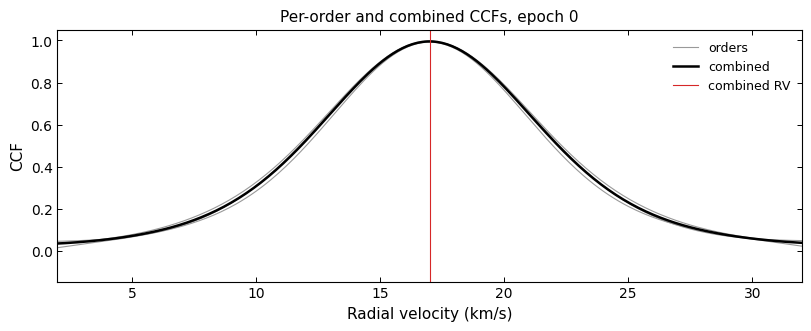

In [8]:
vel = ccf1.Corr["vel"].value
fig, ax = plt.subplots()
for i, cc in enumerate(ccf1.Corr["corr"]):
    plot_curve(ax, vel, cc, color=GREY, lw=0.8, label="orders" if i == 0 else None)
plot_curve(ax, vel, comb["corr"], lw=1.8, label="combined")
ax.axvline(comb["RV"], color=MODEL_COLOR, lw=0.8, label="combined RV")
ax.set_xlim(comb["RV"] - 15, comb["RV"] + 15)
ax.set_xlabel("Radial velocity (km/s)")
ax.set_ylabel("CCF")
ax.set_title("Per-order and combined CCFs, epoch 0")
ax.legend()
plt.show()

`output='loglike'` makes Zucker's (2003) log-likelihood the primary curve instead of the CCF:
$\ln L(v) = -\sum_i \tfrac{N_i}{2}\ln\left(1 - C_i^2(v)\right)$, summed over the orders (and equal to
$-\tfrac{N}{2}\ln(1 - C^2)$ of the combined CCF). Its curvature at the peak is the error formula
above, so the RV and its uncertainty are the same in both modes; `Corr['loglike']` and
`CorrCombined['loglike']` are stored either way.

same RV and error as from the CCF: True


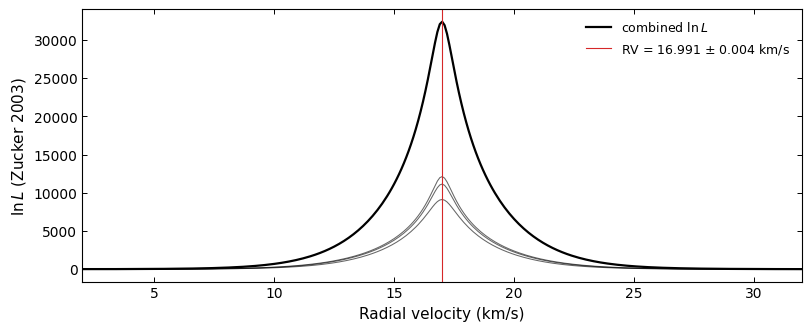

In [9]:
ccf_lnl = CCF1d().cross_correlate(sim_obs.spec_list[0], template, dv=0.1, vel_bound=40,
                                  errors_per_order=True, output="loglike").combine()
same = ccf_lnl.CorrCombined["RV"] == comb["RV"] and ccf_lnl.CorrCombined["eRV"] == comb["eRV"]
print(f"same RV and error as from the CCF: {same}")
fig = ccf_lnl.plot(alpha=0.6)
fig.axes[0].set_xlim(comb["RV"] - 15, comb["RV"] + 15)
plt.show()

## 4. Are the error bars honest?

With the truth known we can check: over many epochs, the scatter of (measured − true) should
match the reported uncertainties. `Observations.calc_rv_against_template` runs the CCF and the
combination for every epoch and stores `vels` and `evels` (km/s).

In [10]:
sim_obs.calc_rv_against_template(template, dv=0.1, vel_bound=40)
resid = sim_obs.vels - sim_obs.truth.rv_kms[:, 0]
n = resid.size

print(f"scatter of (measured - true): {np.std(resid, ddof=1) * 1e3:.2f} m/s")
print(f"mean reported uncertainty:    {np.mean(sim_obs.evels) * 1e3:.2f} m/s")
print(f"ratio: {np.std(resid, ddof=1) / np.mean(sim_obs.evels):.2f}  "
      f"(1 expected; ±{1 / np.sqrt(2 * (n - 1)):.2f} from {n} epochs alone)")
print(f"within 1σ of the truth: {np.mean(np.abs(resid) < sim_obs.evels):.0%}  (68% expected)")

scatter of (measured - true): 3.31 m/s
mean reported uncertainty:    3.50 m/s
ratio: 0.95  (1 expected; ±0.09 from 60 epochs alone)
within 1σ of the truth: 73%  (68% expected)


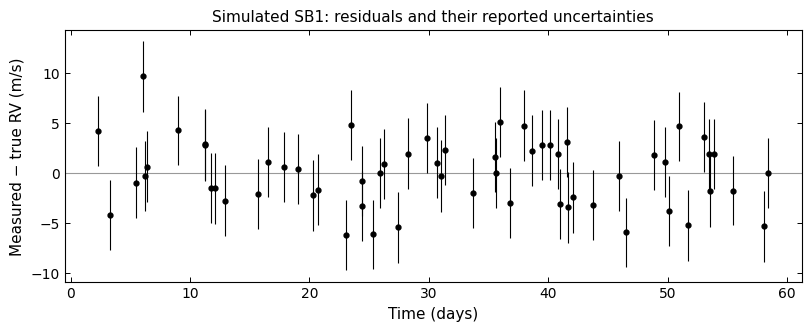

In [11]:
fig, ax = plt.subplots()
ax.axhline(0, color=GREY, lw=0.8)
plot_points(ax, times, resid * 1e3, sim_obs.evels * 1e3)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Measured − true RV (m/s)")
ax.set_title("Simulated SB1: residuals and their reported uncertainties")
plt.show()

The noise here is white on the native pixels, which is what the uncertainty formula assumes.

## 5. Real data: TOI-677 with NRES

Now the full recipe on the 12 bundled NRES spectra. First, the orders and the preprocessing that
`sparta.instruments` recommends for this product: drop the 10 reddest and 17 bluest orders,
then `preprocess` every spectrum, in this order: trim the unexposed margins and the edges,
resample to an even grid, replace cosmic-ray spikes, band-pass filter (removes the continuum,
leaving a zero-continuum spectrum, and the pixel-to-pixel noise) and finally taper the order ends.

The order matters. The margins (flux below 10% of the order median) must go *before* the
continuum is removed: filtering a jump from ~0 to the continuum level would turn it into a
spurious step at the order edge. The taper comes last, acting on a spectrum whose continuum is
already zero.

In [12]:
nres = Observations(survey="NRES", target_visits_lib="data/TOI677/")
rec = instruments.get("NRES").recommended
nres.select_orders(list(rec.drop_orders), remove=True)
raw = copy.deepcopy(nres.spec_list[0])
nres.preprocess(**rec.preprocess)
print(f"{len(nres.spec_list[0].wv)} orders kept; preprocess settings: {rec.preprocess}")

40 orders kept; preprocess settings: {'n_trim': 100, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'filter_lowcut': 4, 'filter_highcut': 0.15, 'alpha': 0.3}


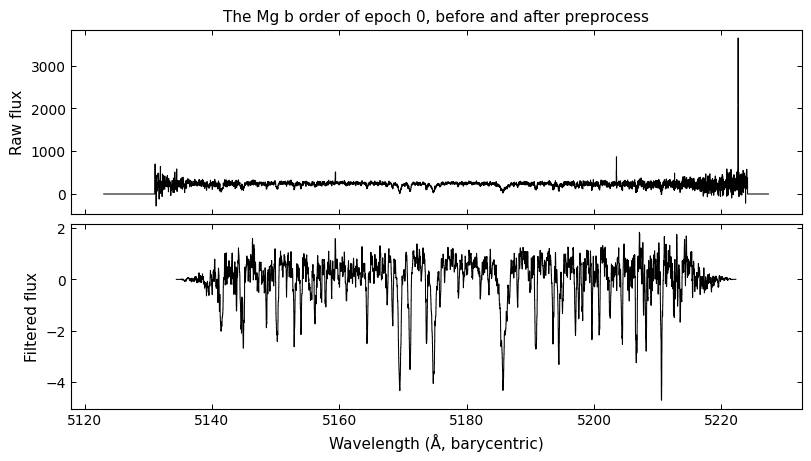

In [13]:
o = next(i for i, w in enumerate(raw.wv) if w[0] < 5175 < w[-1])     # the Mg b order
fig, axs = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
plot_data(axs[0], raw.wv[o], raw.sp[o])
axs[0].set_ylabel("Raw flux")
axs[0].set_title("The Mg b order of epoch 0, before and after preprocess")
plot_data(axs[1], nres.spec_list[0].wv[o], nres.spec_list[0].sp[o])
axs[1].set_ylabel("Filtered flux")
axs[1].set_xlabel("Wavelength (Å, barycentric)")
plt.show()

**The template.** A PHOENIX model from the bundled cache (5800 K, log g 3.5, [Fe/H] +0.5, the
closest bundled model; a template mismatch lowers the CCF peak and so inflates the errors).
We broaden it for rotation and for the NRES resolving
power, cut it into the observed orders (with a 150 km/s margin for the scan), and pass it
through the same preprocessing as the data. NRES does not document its wavelength frame, so we
keep PHOENIX's vacuum wavelengths (notebook 01).

In [14]:
spec0 = nres.spec_list[0]
lo, hi = min(w[0] for w in spec0.wv), max(w[-1] for w in spec0.wv)

template = Template.from_phoenix(5800, 3.5, 0.5, wave_range=(lo - 10, hi + 10))
template.broaden_rotational(vsini=6.0, epsilon=0.5)
template.broaden_instrumental(resolution=instruments.get("NRES").instrument.resolving_power)
template.cut_multiorder_like(spec0, margins=150)
template.model.preprocess(**rec.preprocess)
print(f"template: {len(template.model.wv)} orders, {lo - 10:.0f}-{hi + 10:.0f} Å")

template: 40 orders, 4566-7601 Å


In [15]:
nres.calc_rv_against_template(template, dv=rec.dv_kms, vel_bound=100)

by_time = np.argsort(nres.time_list)                      # files are not in time order
t, rv_nres, erv_nres = np.asarray(nres.time_list)[by_time], nres.vels[by_time], nres.evels[by_time]
print(f"mean RV = {rv_nres.mean():.3f} km/s, rms = {rv_nres.std() * 1e3:.0f} m/s, "
      f"median uncertainty = {np.median(erv_nres) * 1e3:.0f} m/s")

mean RV = 38.172 km/s, rms = 75 m/s, median uncertainty = 24 m/s


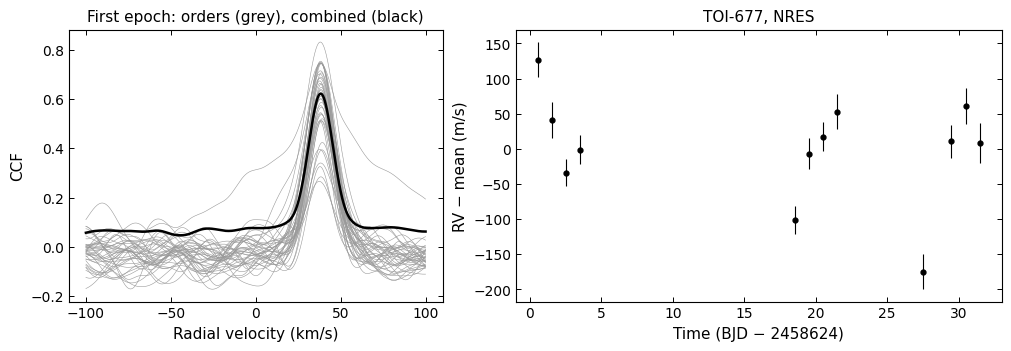

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": (1, 1.3)})
first = nres.ccf_list[by_time[0]]
plot_curve(axs[0], first.Corr["vel"].value, first.Corr["corr"].T, color=GREY, lw=0.4)
plot_curve(axs[0], first.CorrCombined["vel"].value, first.CorrCombined["corr"], lw=1.8)
axs[0].set_xlabel("Radial velocity (km/s)")
axs[0].set_ylabel("CCF")
axs[0].set_title("First epoch: orders (grey), combined (black)")
plot_points(axs[1], t, (rv_nres - rv_nres.mean()) * 1e3, erv_nres * 1e3)
axs[1].set_xlabel(f"Time (BJD − {nres.first_time})")
axs[1].set_ylabel("RV − mean (m/s)")
axs[1].set_title("TOI-677, NRES")
plt.show()

TOI-677 varies by far more than its error bars: it hosts a giant planet on an 11-day
eccentric orbit (Jordán et al. 2020), and notebooks 05-06 show how to look for such a period.
One caveat: band-pass filtering correlates the noise, so after `preprocess` the uncertainties
are no longer exactly calibrated (the `CCF1d.cross_correlate` documentation quantifies it);
simulate your own setup when exact errors matter.

## A note on `velocity_convention`

A measured wavelength ratio becomes a velocity through a convention. SPARTA uses 'cz'
($\lambda_{\rm obs}/\lambda_{\rm rest} = 1 + v/c$, the IAU convention) by default;
`velocity_convention='relativistic'` uses the special-relativistic Doppler formula instead. The
two differ by about $v^2/2c$:

In [17]:
one = nres.spec_list[0]
rv_cz = CCF1d().cross_correlate(one, template, dv=rec.dv_kms, vel_bound=100).combine().CorrCombined["RV"]
rv_rel = CCF1d().cross_correlate(one, template, dv=rec.dv_kms, vel_bound=100,
                                 velocity_convention="relativistic").combine().CorrCombined["RV"]
print(f"cz - relativistic = {(rv_cz - rv_rel) * 1e3:.3f} m/s;  v²/2c = {rv_cz ** 2 / (2 * c) * 1e3:.3f} m/s")

cz - relativistic = 2.446 m/s;  v²/2c = 2.446 m/s


Small, but not negligible for precise work: compare RVs only within one convention.

## Summary / next

- The CCF is a Pearson correlation of the spectrum with the shifted template; its peak is the RV.
- The uncertainty comes from the peak's height and curvature and the number of *independent*
  pixels; on a simulated star the reported errors match the actual scatter.
- Orders are combined by maximum likelihood (Zucker 2003): an inverse-variance weighting.
- Real data need preprocessing and a broadened template processed the same way:
  `Observations.calc_rv_against_template` does the rest.

**Next:** `03_double_lined_todcor.ipynb`: two stars at once.